# From FaIR emissions to synthetic North Atlantic tropical cyclones

What does a change in global temperature actually do to a storm simulation? Follow one September in 2050. FaIR turns the SSP2-4.5 pathway into a global temperature. A regional emulator draws an ocean–atmosphere background in EOF coordinates and evolves daily winds with a linear inverse model (LIM). Coupled FAST then moves and intensifies disturbances in those fields. Every storm plotted below comes from an integration performed by this notebook.

The experiment has two comparisons. First, switch between LIM and the TC package's hourly Fourier winds on identical September backgrounds and seed panels. Second, compare early storm intensity and travel distance with historical North Atlantic best tracks on the same six-hour grid.

**To run it** use the current repository with the twelve-month weights installed, install `requirements-notebook.txt` in the notebook's Python environment, then choose **Restart Kernel and Run All**. The scenario inputs, historical observations, solver and geographic grids are included. The benchmark writes hourly tracks, one row per attempted seed, figures and tables under `runs/fair_to_tc/`. The cell below controls the sample size and number of CPU workers. [Weight installation](../README.md) · [Regional model derivation](../reports/annual_lim_linear_algebra.md)

In [1]:
import os
import sys
from pathlib import Path
for key in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[key] = "1"
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/annual_lim/model.py").is_file())
sys.path[:0] = [str(root / "src"), str(root / "notebooks")]
candidates = [Path(os.environ["ANNUAL_LIM_WEIGHTS"])] if "ANNUAL_LIM_WEIGHTS" in os.environ else []
candidates += [root / "weights", root / "runs/annual_lim/weights", root / "work/weights"]
weights = next((p for p in candidates
                if (p / "09/model.json").is_file()), None)
if weights is None:
    raise FileNotFoundError("Install the v1.0.0 weights using the command in README.md.")
data = root / "notebooks/data"
out = root / "runs/fair_to_tc"
out.mkdir(parents=True, exist_ok=True)

import hashlib
import json
import multiprocessing as mp
import platform
from concurrent.futures import ProcessPoolExecutor
from importlib.metadata import version
from time import perf_counter

%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from threadpoolctl import threadpool_limits
from annual_lim.model import MonthlyModel
from annual_lim.sample import event, forcing
from tc_emulator.sampling import fair_years
from tc_emulator.tc_adapter import geography
from tc_benchmark import DAYS, METHODS, MONTH, paired_rates, run_pair, window_samples

threads = threadpool_limits(limits=1)
seed = 20261119
historical_years = list(range(1985, 2021, 5))
future_year = 2050
future_events = 8
seeds_per_event = 128
workers = max(1, int(os.environ.get("TC_DEMO_WORKERS", "2")))
manifest = json.loads((data / "sources.json").read_text())
for filename, expected in manifest["sha256"].items():
    assert hashlib.sha256((data / filename).read_bytes()).hexdigest() == expected
assert version("fair") == manifest["fair"]["version"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100,
                     "axes.titlelocation": "left", "font.size": 10, "savefig.dpi": 150})
colors = {"Pure LIM": "#007875", "Native Fourier": "#ba532b", "HURDAT2": "#413e70"}
print(f"{len(historical_years)} historical + {future_events} future panels, "
      f"{seeds_per_event} seeds per panel, {len(METHODS)} drivers, {workers} workers")

8 historical + 8 future panels, 128 seeds per panel, 2 drivers, 4 workers


## 1 · Run FaIR on the SSP2-4.5 pathway

The small input archive contains emissions, prescribed concentrations and prescribed radiative forcing in the units and species order expected by FaIR. It can be regenerated from the three original RCMIP tables. It contains no temperature trajectory. Here we run FaIR 2.2.4 with one published parameter configuration (2451, calibration 1.4.1) and turn off stochastic internal temperature noise. This gives one forced global surface air temperature path. The experiment samples regional weather uncertainty separately. [FaIR calibration](https://docs.fairmodel.net/en/v2.2.4/examples/calibrated_constrained_ensemble.html) · [RCMIP 5.1.0](https://doi.org/10.5281/zenodo.4589756) · [Input preparation](prepare_tc_inputs.py)

In [2]:
# FaIR disables its progress bar below, so a Jupyter widget backend is optional.
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")
    from fair import FAIR
from fair.interface import fill, initialise
from fair.io import read_properties

start = perf_counter()
fair = FAIR(ch4_method="Thornhill2021")
config_id = 2451
fair.define_time(1750, 2101, 1)
fair.define_scenarios(["ssp245"])
fair.define_configs([config_id])
fair.define_species(*read_properties(filename=data / "fair_species.csv"))
fair.allocate()
with np.load(data / "rcmip_ssp245.npz", allow_pickle=False) as inputs:
    np.testing.assert_array_equal(inputs["species"], fair.species)
    np.testing.assert_array_equal(inputs["timebounds"], fair.timebounds)
    np.testing.assert_array_equal(inputs["timepoints"], fair.timepoints)
    for name in ("emissions", "concentration", "forcing"):
        fill(getattr(fair, name), inputs[name], scenario="ssp245", config=config_id)
fair.fill_species_configs(data / "fair_species.csv")
fair.override_defaults(data / "fair_2451.csv")
fill(fair.climate_configs["stochastic_run"], False)
params = pd.read_csv(data / "fair_2451.csv", index_col=0).loc[config_id]
for name in ("Solar", "Volcanic"):
    fill(fair.forcing, fair.forcing.sel(specie=name) * params[f"forcing_scale[{name}]"], specie=name)
initialise(fair.concentration, fair.species_configs["baseline_concentration"])
for a in (fair.forcing, fair.temperature, fair.cumulative_emissions,
          fair.airborne_emissions, fair.ocean_heat_content_change):
    initialise(a, 0)
fair.run(progress=False)
surface = fair.temperature.sel(scenario="ssp245", config=config_id, layer=0)
fair_seconds = perf_counter() - start
assert np.isfinite(surface).all()
print(f"Ran {len(fair.timepoints)} annual steps, {len(fair.species)} species, one climate configuration.")

Ran 351 annual steps, 61 species, one climate configuration.


FaIR reports temperature at year boundaries. With linear interpolation between adjacent boundaries, the annual mean for year $y$ is $a_y=[T(y)+T(y+1)]/2$. The regional model uses $g_y=a_y-\frac{1}{51}\sum_{j=1850}^{1900}a_j$. The CSV below exercises the same forcing interface as the command-line sampler. A FaIRGP path with the documented columns can use that interface as well.

2050 global warming = 1.813 K relative to 1850–1900


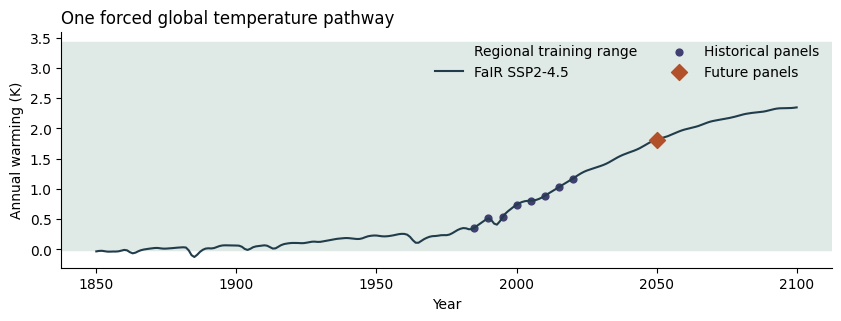

In [3]:
bounds_file = out / "fair_ssp245_timebounds.csv"
pd.DataFrame({"time": fair.timebounds, "forced_temperature": surface.values, "unit": "K",
              "baseline": "1750 initial state", "scenario": "ssp245", "draw_id": str(config_id),
              "temperature_definition": "forced global surface air temperature"}).to_csv(bounds_file, index=False)
warming = fair_years(bounds_file).set_index("year").g
g_future, origin = forcing(None, bounds_file, future_year, "ssp245", str(config_id))
means = (surface.values[:-1] + surface.values[1:]) / 2
years = fair.timebounds[:-1].astype(int)
baseline = means[(years >= 1850) & (years <= 1900)].mean()
np.testing.assert_allclose(warming.loc[years], means - baseline, atol=1e-12)
print(f"{future_year} global warming = {g_future:.3f} K relative to 1850–1900")
model = MonthlyModel(weights, MONTH)
fig, ax = plt.subplots(figsize=(8.3, 3.1), layout="constrained")
ax.axhspan(model.cal.g_min, model.cal.g_max, color="#dfe9e6", label="Regional training range")
ax.plot(warming.loc[1850:], color="#213d4b", label="FaIR SSP2-4.5")
ax.scatter(historical_years, warming.loc[historical_years], color=colors["HURDAT2"], s=24, label="Historical panels")
ax.scatter(future_year, g_future, color="#b25129", s=66, marker="D", label="Future panels", zorder=4)
ax.set(xlabel="Year", ylabel="Annual warming (K)", title="One forced global temperature pathway")
ax.legend(ncol=2, frameon=False)
fig.savefig(out / "warming.png")
plt.show()

## 2 · Decode an EOF background and evolve the wind

The September weights contain regional empirical orthogonal functions (EOFs) fitted to MPI-ESM1-2-LR. The background draw is $z=m(g)+F(g)\epsilon$, where $m(g)$ is the mean vector, $F(g)$ shapes the covariance, and the entries of $\epsilon$ are independent standard normal variates. Decoding converts 78 scores into SST, mixed-layer depth, ocean stratification, pressure and atmospheric profiles. Each map is its training mean plus a weighted sum of EOFs. In panel A, adding one training standard deviation of the first SST score makes the displayed temperature change. Its sign follows the stored EOF convention.

The wind model first samples a stationary Gaussian state with two daily lags, then advances it with a fitted transition matrix and fresh Gaussian innovations. A fitted 5–20 day memory term acts on these states. Adding the background-dependent mean produces 120 daily wind scores. Decoding them gives $u$ and $v$ at 250 and 850 hPa. All disturbances in this LIM event experience the same sequence. [Model equations and estimation](../reports/annual_lim_linear_algebra.md)

In [4]:
demo = event(weights, MONTH, future_year, g_future, DAYS, seed, 0, 0)
z = model.draw_z(g_future, future_year, seed, 0)
np.testing.assert_allclose(z, demo.background_pc)
decoded = model.rep.decode(z[None])
np.testing.assert_allclose(decoded["sst"][0], demo.sst, equal_nan=True)
scores = model.pc_path(g_future, z, DAYS + 3, future_year, seed, 0, 0)
np.testing.assert_allclose(scores, demo.wind_pc)
np.testing.assert_allclose(model.rep.blocks["wind"].inverse(scores), demo.wind)
display(pd.DataFrame([
    {"EOF block": name, "scores": len(block.variance),
     "retained training variance (%)": 100 * block.variance.sum() / block.total_variance}
    for name, block in model.rep.blocks.items()
]).round(1))
print(f"{len(z)} background scores; daily field {demo.wind.shape} (time, component, lat, lon).")
print(f"{DAYS} integration days with wind nodes from day −1 through day {DAYS+1}.")

,EOF block,scores,retained training variance (%)
0,sst,18,89.4
1,ocean,18,56.5
2,psl,14,92.2
3,profiles,28,87.7
4,wind,120,88.0


78 background scores; daily field (18, 4, 36, 58) (time, component, lat, lon).
15 integration days with wind nodes from day −1 through day 16.


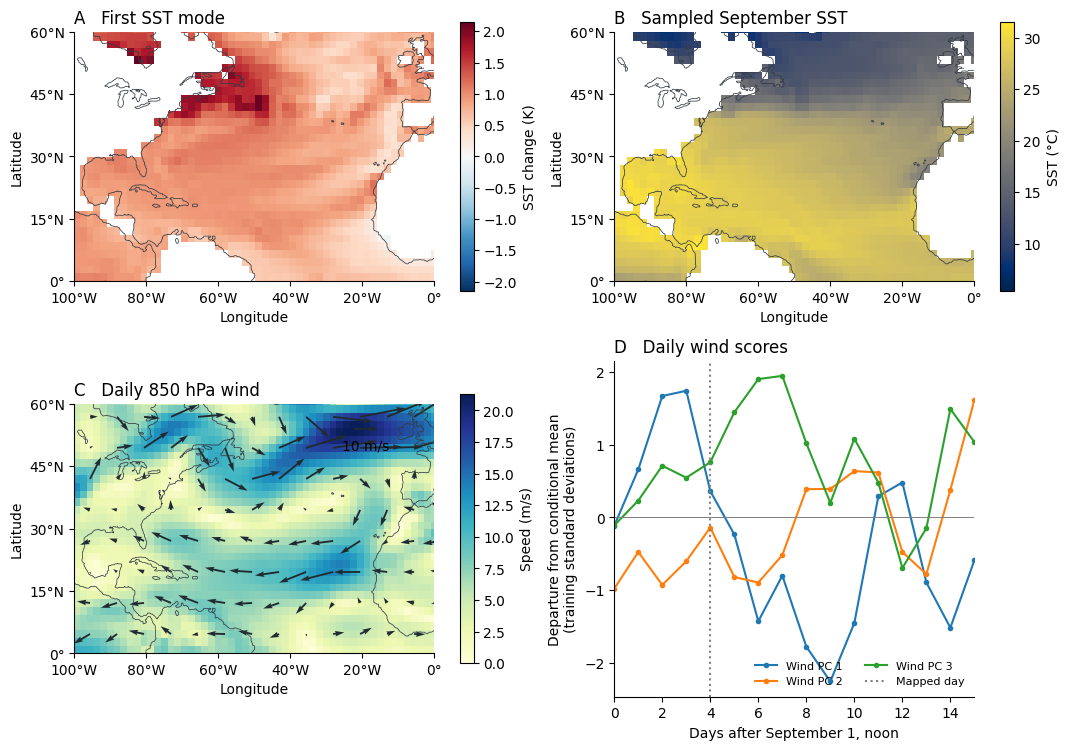

In [5]:
from matplotlib.ticker import FuncFormatter
_, _, _, land, _ = geography()
coast_x = np.linspace(-100, 0, 501)
coast_y = np.linspace(0, 60, 301)
land_fraction = land(coast_x + 360, coast_y).T

def basin_map(ax):
    ax.contour(coast_x, coast_y, land_fraction, levels=[0.5], colors="#333b44", linewidths=0.55)
    ax.set(xlim=(-100, 0), ylim=(0, 60), xlabel="Longitude", ylabel="Latitude")
    ax.set_xticks([-100, -80, -60, -40, -20, 0])
    ax.set_yticks([0, 15, 30, 45, 60])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):g}°W" if x else "0°"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}°N" if y else "0°"))
    ax.set_aspect(1 / np.cos(np.deg2rad(30)))

sst = model.rep.blocks["sst"]
score = np.zeros((1, len(sst.variance)))
score[0, 0] = np.sqrt(sst.variance[0])
pattern = (sst.inverse(score) - sst.inverse(0 * score))[0, 0]
x, y = demo.lon.values - 360, demo.lat.values
day = 4     # elapsed time since September 1 at noon
wind = demo.wind.sel(t_seconds=day * 86400)
u, v = (wind.sel(component=k).values for k in ("u850", "v850"))
fig, axs = plt.subplots(2, 2, figsize=(10.6, 7.6), layout="constrained")
peak = np.nanmax(np.abs(pattern))
panels = [(axs[0, 0], pattern, "RdBu_r", -peak, peak, "A   First SST mode", "SST change (K)"),
          (axs[0, 1], demo.sst.values - 273.15, "cividis", None, None, "B   Sampled September SST", "SST (°C)"),
          (axs[1, 0], np.hypot(u, v), "YlGnBu", 0, None, "C   Daily 850 hPa wind", "Speed (m/s)")]
for ax, field, cmap, low, high, title, units in panels:
    im = ax.pcolormesh(x, y, field, cmap=cmap, vmin=low, vmax=high, shading="auto")
    basin_map(ax)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=.8, label=units)
q = axs[1, 0].quiver(x[::4], y[::4], u[::4, ::4], v[::4, ::4], color="#202b31", scale=145)
axs[1, 0].quiverkey(q, .81, .90, 10, "10 m/s", coordinates="axes", labelpos="S")
ax = axs[1, 1]
elapsed = demo.t_seconds.values / 86400
for k in range(3):
    anomaly = (scores[:, k] - demo.conditional_wind_pc.values[k]) / np.sqrt(model.rep.blocks["wind"].variance[k])
    ax.plot(elapsed, anomaly, marker=".", label=f"Wind PC {k+1}")
ax.axhline(0, color="0.5", lw=.7)
ax.axvline(day, color="0.5", ls=":", label="Mapped day")
ax.set(title="D   Daily wind scores", xlabel="Days after September 1, noon",
       ylabel="Departure from conditional mean\n(training standard deviations)", xlim=(0, DAYS))
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.savefig(out / "eof_lim.png")
plt.show()

## 3 · Release the same disturbances into two weather systems

Coupled FAST moves each disturbance with intensity-dependent steering and beta drift. Potential intensity, moisture, vertical wind shear, ocean mixing and land conditions enter the intensity calculation. Random candidate locations are area-uniform in the project's seeding rectangle. FAST screens ocean location, latitude, potential intensity and ventilation. The project counts a TC when the two-day axisymmetric wind reaches 6.5 m/s, its peak reaches 15 m/s and the peak surface wind reaches 18 m/s. A landfall requires an accepted TC and an hourly sea-to-land crossing with surface wind at least 18 m/s. Failed seeds stay in the denominator. [FAST physics and source](https://github.com/linjonathan/tropical_cyclone_risk/tree/a540a1ed86b121f7244557edb691b40561b81939) · [Seeding and classification](../src/tc_emulator/tc_adapter.py)

Each event gets an independent seed panel, one thermodynamic background and one conditional mean wind. Both drivers receive identical seed positions, initial intensities and filter draws. The Fourier driver receives the LIM's exact zero-lag, four-component grid-point covariance at the selected warming. It then uses the native 15-harmonic generator and draws phases separately for each disturbance. The LIM driver shares one spatially varying daily realization across disturbances. The comparison therefore includes spatial coherence, temporal evolution and the choice of sharing weather across seeds. [Covariance calculation and paired integrations](tc_benchmark.py)

The 15-day window begins on September 1. The historical panels sample eight Septembers, spaced five years apart. The future panels sample independent backgrounds and winds at one 2050 warming level. The counts measure outcomes per attempted disturbance. An annual storm count would require a separate calibration of seeding exposure.

In [6]:
# run_pair calls event(...) and tracks(...) for each driver and returns hourly tracks.
historical = [(weights, "Historical", i, y, float(warming.loc[y]), seed, seeds_per_event)
              for i, y in enumerate(historical_years)]
future = [(weights, "Future", i, future_year, g_future, seed, seeds_per_event)
          for i in range(future_events)]
cases = historical + future
started = perf_counter()
if workers == 1:
    results = [run_pair(case) for case in cases]
else:
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as pool:
        results = list(pool.map(run_pair, cases))
wall_seconds = perf_counter() - started
paths = xr.concat([p for p, _, _ in results], dim="case", combine_attrs="drop")
attempts = pd.concat([a for _, a, _ in results], ignore_index=True)
times = pd.DataFrame([t for _, _, ts in results for t in ts])
assert len(attempts) == len(cases) * seeds_per_event * len(METHODS)
paired = attempts.set_index(["case", "method", "seed_id"]).sort_index()
seed_columns = ["lon", "lat", "v_init", "filter_draw", "offset_s"]
pd.testing.assert_frame_equal(paired.xs(METHODS[0], level="method")[seed_columns],
                              paired.xs(METHODS[1], level="method")[seed_columns])
assert (attempts.landfall <= attempts.tc).all() and (attempts.tc <= attempts.integrated).all()
assert paths.sizes["elapsed_s"] == 24 * DAYS + 1
for method in METHODS:
    for case_id, group in attempts[attempts.method == method].groupby("case"):
        track = paths.vmax.sel({"method": method, "case": case_id})
        np.testing.assert_array_equal(np.isfinite(track).any("elapsed_s"), group.sort_values("seed_id").integrated)
paths.attrs.update(title="North Atlantic September paired Coupled FAST trajectories",
    month=MONTH, duration_days=DAYS, weather_model=model.meta["id"], seed=seed,
    forcing="FaIR 2.2.4 SSP2-4.5, calibration 1.4.1 configuration 2451",
    event_origin="September 1 at noon in the statistical month",
    outcomes="Join attempts.parquet on case, method and seed_id. Screened seeds have no track.")
for field, unit in {"storm_lon":"degrees_east", "storm_lat":"degrees_north",
                    "vmax":"m s-1", "deep_shear":"m s-1", "elapsed_s":"s", "warming_K":"K"}.items():
    paths[field].attrs["units"] = unit
paths.warming_K.attrs["long_name"] = "annual global temperature relative to 1850–1900"
attempts.to_parquet(out / "attempts.parquet", index=False)
paths.to_netcdf(out / "tracks.nc", encoding={v: {"zlib": True, "complevel": 2} for v in paths.data_vars})
times.to_csv(out / "event_timings.csv", index=False)
print(f"{len(attempts):,} seed attempts across both drivers; {attempts.integrated.sum()} "
      f"passed screening. {paths.sizes['elapsed_s']} possible hourly positions per integration.")

4,096 seed attempts across both drivers; 1632 passed screening. 361 possible hourly positions per integration.


## 4 · Benchmark storm formation, landfall and runtime

The table gives the full count at each stage. Peak wind is the median of the hourly maximum surface winds of **accepted storms** within their 15-day integration windows. A run can stop earlier at dissipation or basin exit. For the paired differences we resample entire event pairs 5,000 times, leaving disturbances that share weather together. The intervals describe sampling variation across these few panels.

For a reference in the 2050 model climate, a separate benchmark drives FAST with daily MPI SSP2-4.5 winds from eight held-out members. It compares the wind and storm distributions with these same two weather generators, including the FaIR-only deployment setting. [2050 MPI daily replay and figure](../reports/mpi2050/README.md)

In [7]:
group = attempts.groupby(["period", "method"], sort=False)
summary = group.agg(events=("case", "nunique"), attempts=("seed_id", "size"),
                    integrated=("integrated", "sum"), TCs=("tc", "sum"), landfalls=("landfall", "sum"))
summary["TC_per_100_attempts"] = 100 * summary.TCs / summary.attempts
summary["landfalls_per_100_attempts"] = 100 * summary.landfalls / summary.attempts
summary["median_peak_wind_ms"] = attempts[attempts.tc].groupby(["period", "method"]).lmi.median()
summary = summary.reindex(pd.MultiIndex.from_product([["Historical", "Future"], METHODS], names=summary.index.names))
summary.to_csv(out / "tc_counts.csv")
display(summary.round(2))
deltas = paired_rates(attempts, seed)
deltas.to_csv(out / "paired_differences.csv", index=False)
display(deltas.round(2))
timing = times.groupby("method").seconds.sum().to_frame("summed_track_call_s")
timing["attempts"] = attempts.groupby("method").size()
timing["attempts_per_solver_s"] = timing.attempts / timing.summed_track_call_s
display(timing.round(2))
print(f"FaIR setup + climate integration: {fair_seconds:.2f} s. Full paired panel wall time: {wall_seconds:.1f} s "
      f"({workers} processes, one BLAS thread each).")
timing.to_csv(out / "solver_timing.csv")
_ = (out / "run.json").write_text(json.dumps(dict(seed=seed, history_years=historical_years, future_year=future_year,
    future_g_K=g_future, baseline="1850–1900", fair_config=config_id, fair_s=fair_seconds, panel_wall_s=wall_seconds,
    weather_model=model.meta["id"], period_days=DAYS, seeds_per_event=seeds_per_event,
    future_events=future_events, workers=workers, cpu_arch=platform.machine(), python=platform.python_version(),
    packages={k:version(k) for k in ("fair", "numpy", "scipy", "pandas", "xarray", "torch")}), indent=2) + "\n")

events  attempts  integrated  TCs  landfalls  \
period     method                                                         
Historical Pure LIM             8      1024         420   27         18   
           Native Fourier       8      1024         414   31         23   
Future     Pure LIM             8      1024         409   32         29   
           Native Fourier       8      1024         389   22         16   

                           TC_per_100_attempts  landfalls_per_100_attempts  \
period     method                                                            
Historical Pure LIM                       2.64                        1.76   
           Native Fourier                 3.03                        2.25   
Future     Pure LIM                       3.12                        2.83   
           Native Fourier                 2.15                        1.56   

                           median_peak_wind_ms  
period     method                               
Historical Pure LIM                      38.54  
           Native Fourier                35.02  
Future     Pure LIM                      37.54  
           Native Fourier                35.38

,period,outcome,paired_events,lim_minus_fourier_pp,event_boot_low_pp,event_boot_high_pp
0,Historical,tc,8,-0.39,-1.76,1.66
1,Historical,landfall,8,-0.49,-2.05,1.76
2,Future,tc,8,0.98,-0.29,2.25
3,Future,landfall,8,1.27,0.20,2.34


,summed_track_call_s,attempts,attempts_per_solver_s
method,,,
Native Fourier,31.6,2048,64.80
Pure LIM,21.6,2048,94.81


FaIR setup + climate integration: 0.52 s. Full paired panel wall time: 17.4 s (4 processes, one BLAS thread each).


Solver seconds sum time inside the track calls across workers and include screening, integration, and recording hourly diagnostics. They exclude background generation and construction of the Fourier provider. Panel wall time also includes those operations and process startup. Each driver can integrate a different number of disturbances, which affects throughput.

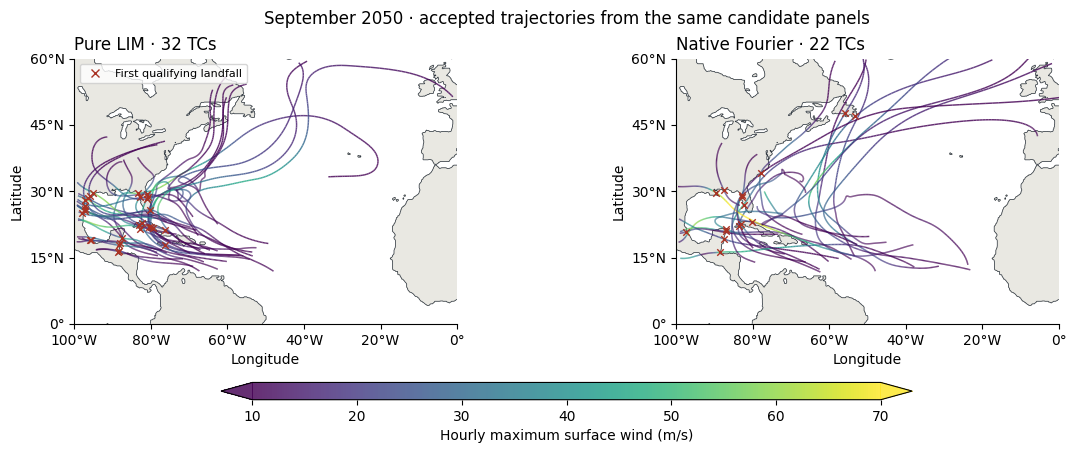

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
norm = Normalize(10, 70, clip=True)
for ax, method in zip(axs, METHODS):
    ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#e9e8e2"])
    basin_map(ax)
    subset = attempts[(attempts.period == "Future") & (attempts.method == method) & attempts.tc]
    segments, speeds = [], []
    for row in subset.itertuples(index=False):
        t = paths.sel({"case": row.case, "method": method, "seed_id": row.seed_id})
        ok = np.isfinite(t.vmax.values)
        xy = np.column_stack((t.storm_lon.values[ok] - 360, t.storm_lat.values[ok]))
        segments.extend(np.stack((xy[:-1], xy[1:]), axis=1))
        speeds.extend((t.vmax.values[ok][:-1] + t.vmax.values[ok][1:]) / 2)
    lines = LineCollection(segments, cmap="viridis", norm=norm, linewidths=1.05, alpha=.82)
    lines.set_array(np.asarray(speeds))
    ax.add_collection(lines)
    hits = subset[subset.landfall]
    ax.scatter(hits.landfall_lon - 360, hits.landfall_lat, marker="x", s=22,
               color="#a93324", linewidth=1, zorder=4)
    ax.set_title(f"{method} · {len(subset)} TCs")
fig.suptitle(f"September {future_year} · accepted trajectories from the same candidate panels")
fig.colorbar(lines, ax=axs, location="bottom", shrink=.58, aspect=40, label="Hourly maximum surface wind (m/s)",
             extend="both")
axs[0].legend(handles=[Line2D([], [], linestyle="", marker="x", color="#a93324",
                              label="First qualifying landfall")], loc="upper left", fontsize=8)
fig.savefig(out / "tc_tracks.png")
plt.show()

An individual trajectory helps explain why switching the weather driver changes the counts. Take the first future case and seed ID (in numerical order) that qualifies as a TC with both drivers. Both tracks begin with the same initial location and intensity. As their environmental winds and positions diverge, the vertical shear along each path can also change. The monthly ocean background is fixed in both runs.

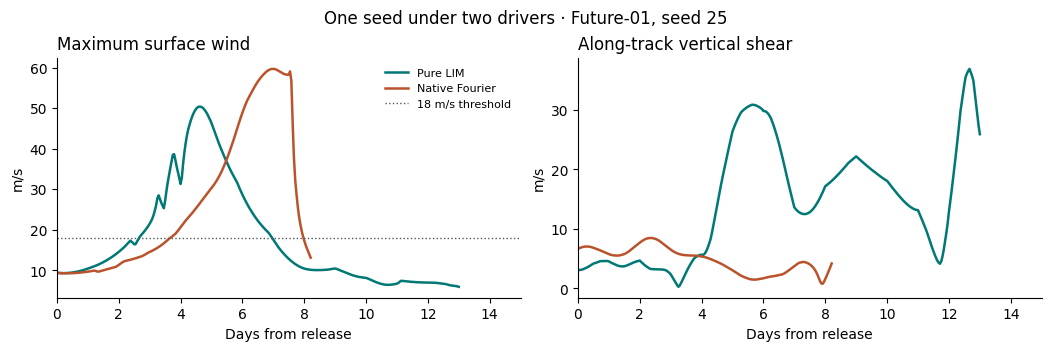

In [9]:
future_rows = attempts[attempts.period == "Future"]
qualified = future_rows.pivot(index=["case", "seed_id"], columns="method", values="tc").all(axis=1)
integrated = future_rows.pivot(index=["case", "seed_id"], columns="method", values="integrated").all(axis=1)
pairs = qualified[qualified].index if qualified.any() else integrated[integrated].index
if len(pairs):
    case_id, seed_id = pairs[0]
    fig, axs = plt.subplots(1, 2, figsize=(10.4, 3.4), layout="constrained")
    for method in METHODS:
        tr = paths.sel({"case": case_id, "method": method, "seed_id": seed_id})
        for ax, var, title in zip(axs, ["vmax", "deep_shear"], ["Maximum surface wind", "Along-track vertical shear"]):
            ax.plot(tr.elapsed_s / 86400, tr[var], color=colors[method], label=method, linewidth=1.8)
            ax.set(title=title, xlabel="Days from release", ylabel="m/s", xlim=(0, DAYS))
    axs[0].axhline(18, ls=":", color="#51575b", lw=1, label="18 m/s threshold")
    axs[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"One seed under two drivers · {case_id}, seed {seed_id}")
    fig.savefig(out / "storm_evolution.png")
    plt.show()
else:
    print("No future seed integrated under both drivers in this panel.")

## 5 · Compare historical storms with NOAA best tracks

Here the comparison is between synthetic storms and the Atlantic HURDAT2 observations for the **same eight historical Septembers**. For each storm, find the first six-hourly tropical fix with wind at least 18 m/s. That fix must occur in September. Keep the storm if that fix and the next eight six-hourly fixes are consecutive, remain tropical and lie in the evaluation region (100°W–0°, 0–60°N). Read the highest wind over those 48 hours and the great-circle distance from the first to the ninth fix. The distance measures net displacement. HURDAT2 uses knots, converted with $1\ \mathrm{kt}=1852/3600\ \mathrm{m\,s^{-1}}$.

The observations sample storms beginning throughout September. Simulated disturbances start on September 1, and their trajectories end after at most 15 days. Historical best tracks contain no record of failed disturbances, so observational comparisons use distributions conditional on qualifying storms. We report the sample sizes after this selection. Future outcomes have no observational counterpart. [NOAA HURDAT2 archive](https://www.nhc.noaa.gov/data/#hurdat) · [Atlantic data format](https://www.nhc.noaa.gov/data/hurdat/hurdat2-format-atl-1851-2021.pdf)

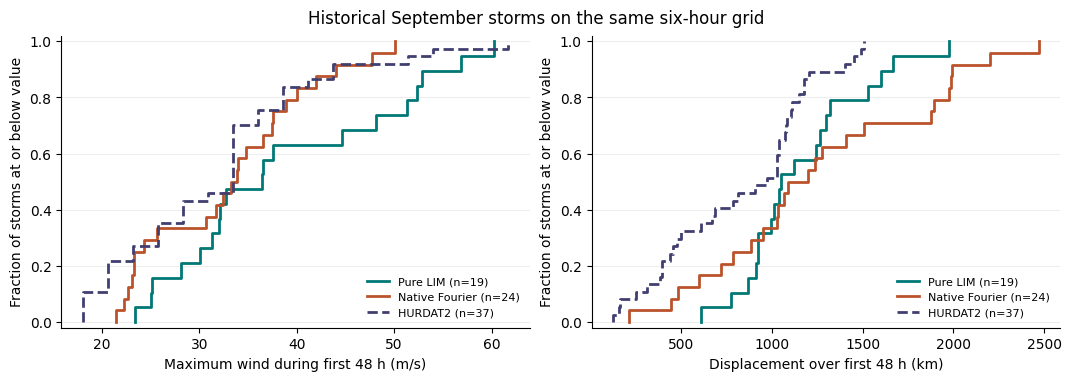

,method,measurement,storms,q25,median,q75,Wasserstein_to_HURDAT2
0,Pure LIM,peak_48h_ms,19,30.69,36.48,49.73,7.05
1,Native Fourier,peak_48h_ms,24,24.07,33.58,37.92,2.34
2,HURDAT2,peak_48h_ms,37,23.15,33.44,36.01,0.00
3,Pure LIM,displacement_48h_km,19,922.53,1051.46,1308.36,335.99
4,Native Fourier,displacement_48h_km,24,856.54,1140.65,1880.66,434.46
5,HURDAT2,displacement_48h_km,37,453.75,971.02,1101.53,0.00


In [10]:
from scipy.stats import wasserstein_distance
windows = window_samples(paths, attempts, data / "hurdat2_synoptic.csv.gz", historical_years)
windows.to_csv(out / "storm_windows.csv", index=False)
historical_windows = windows[windows.period == "Historical"]
obs = historical_windows[historical_windows.method == "HURDAT2"]
stats_rows = []
variables = {"peak_48h_ms": "Maximum wind during first 48 h (m/s)",
             "displacement_48h_km": "Displacement over first 48 h (km)"}
fig, axs = plt.subplots(1, 2, figsize=(10.6, 3.7), layout="constrained")
for ax, (var, label) in zip(axs, variables.items()):
    for method in (*METHODS, "HURDAT2"):
        values = np.sort(historical_windows.loc[historical_windows.method == method, var].dropna().values)
        if len(values):
            ax.ecdf(values, color=colors[method], linewidth=2,
                    linestyle="--" if method == "HURDAT2" else "-", label=f"{method} (n={len(values)})")
        quartiles = np.quantile(values, [.25, .5, .75]) if len(values) else [np.nan] * 3
        distance = wasserstein_distance(values, obs[var]) if len(values) and len(obs) else np.nan
        stats_rows.append((method, var, len(values), *quartiles, distance))
    ax.set(xlabel=label, ylabel="Fraction of storms at or below value", ylim=(-.02, 1.02))
    ax.grid(axis="y", alpha=.22)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Historical September storms on the same six-hour grid")
fig.savefig(out / "tc_observations.png")
plt.show()
comparison = pd.DataFrame(stats_rows, columns=["method", "measurement", "storms", "q25", "median", "q75",
                                               "Wasserstein_to_HURDAT2"])
comparison.to_csv(out / "historical_shapes.csv", index=False)
display(comparison.round(2))

Read each curve from the bottom up. At a cumulative fraction of 0.5 the horizontal coordinate is the median storm. The Wasserstein distance summarizes the gap across **all** quantiles, in m/s or km. It describes the distributions that survive the selection above. The paired TC rates answer a different question about the fraction of all seeded disturbances that develop. The seed-exposure denominator makes that question answerable even when a disturbance never develops.

To explore sampling variability, increase `seeds_per_event` and `future_events` separately. Increasing the seed count adds candidate disturbances in the same large-scale settings. Increasing the number of future events draws additional ocean–atmosphere backgrounds and weather at the selected warming. The two settings estimate different sources of variability. You can join hourly tracks in `tracks.nc` to `attempts.parquet` on `case`, `method` and `seed_id` to inspect an individual storm.